Random Oversampling is the simplest possible fix for class imbalance: randomly duplicate rows from the minority class until it has roughly the same number of samples as the majority class. No new information is created — we're just showing the model the existing minority examples more than once, so it can't afford to ignore them during training.

*In plain English: if you only have 67 Non-Petrol cars but 233 Petrol cars, randomly copy-paste Non-Petrol rows (with replacement) until you also have 233 Non-Petrol rows.*

**After oversampling:**

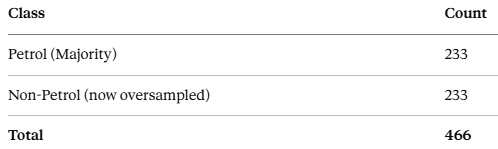

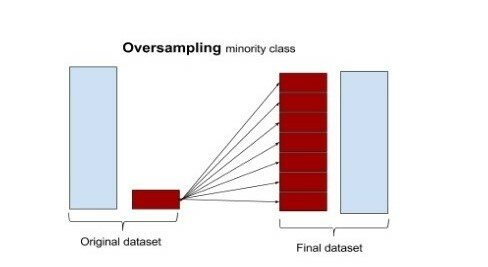

In [ ]:
import pandas as pd
from sklearn.utils import resample

df = pd.read_csv("used_cars_dataset.csv")
df["Class"] = df["Fuel_Type"].apply(lambda x: "Petrol" if x == "Petrol" else "Non-Petrol")

majority = df[df["Class"] == "Petrol"]
minority = df[df["Class"] == "Non-Petrol"]

minority_oversampled = resample(
    minority,
    replace=True,             # sample WITH replacement -> duplicates allowed
    n_samples=len(majority),  # match majority class count (233)
    random_state=42
)

balanced_df = pd.concat([majority, minority_oversampled])
print(balanced_df["Class"].value_counts())
# Petrol        233
# Non-Petrol    233

# Disadvantages

1. Overfitting risk. Because the same 5 Hybrid car rows might now be copied dozens of times, the model can start to memorize those exact rows rather than learning the general pattern of what makes a car a Hybrid. Think of it like a student who repeats one practice question 30 times — they memorize the answer to that specific question rather than understanding the concept.

2. No new information. We haven't taught the model anything about the variety of Non-Petrol cars that might exist beyond our 67 examples.

3. Larger training set, longer training time. Our dataset grew from 300 rows to 466 rows just from balancing this one binary split — with more severe imbalance, this effect is even bigger.

# When to Use Random Oversampling

When your dataset is small, and you can't afford to throw away majority-class data (as undersampling would).
When your model architecture (e.g., regularized logistic regression, tree-based ensembles) is relatively robust to overfitting.